In [1]:
import copy
import os
import random
import shutil
import zipfile
from math import atan2, cos, sin, sqrt, pi, log
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from PIL import Image
from numpy import linalg as LA
from torch import optim, nn
from torch.utils.data import DataLoader, random_split
from torch.utils.data.dataset import Dataset
from torchvision import transforms
from tqdm import tqdm

In [2]:
class DoubleConv(nn.Module):
  def __init__(self, in_channels, out_channels):
    super().__init__()
    self.conv_op = nn.Sequential(
      nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
      nn.ReLU(inplace=True),
      nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
      nn.ReLU(inplace=True)
    )
  def forward(self, x):
    return self.conv_op(x)

In [3]:
class DownSample(nn.Module):
  def __init__(self, in_channels, out_channels):
    super().__init__()
    self.conv = DoubleConv(in_channels, out_channels)
    self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
  def forward(self, x):
    down = self.conv(x)
    p = self.pool(down)
    return down, p

In [4]:
class UpSample(nn.Module):
  def __init__(self, in_channels, out_channels):
    super().__init__()
    self.up = nn.ConvTranspose2d(in_channels, in_channels//2, kernel_size=2, stride=2)
    self.conv = DoubleConv(in_channels, out_channels)
  def forward(self, x1, x2):
    x1 = self.up(x1)
    x = torch.cat([x1, x2], 1)
    return self.conv(x)

In [5]:
class UNet(nn.Module):
  def __init__(self, in_channels, num_classes):
    super().__init__()
    self.down_convolution_1 = DownSample(in_channels, 64)
    self.down_convolution_2 = DownSample(64, 128)
    self.down_convolution_3 = DownSample(128, 256)
    self.down_convolution_4 = DownSample(256, 512)
    self.bottle_neck = DoubleConv(512, 1024)
    self.up_convolution_1 = UpSample(1024, 512)
    self.up_convolution_2 = UpSample(512, 256)
    self.up_convolution_3 = UpSample(256, 128)
    self.up_convolution_4 = UpSample(128, 64)
    self.out = nn.Conv2d(in_channels=64, out_channels=num_classes, kernel_size=1)

  def forward(self, x):
    down_1, p1 = self.down_convolution_1(x)
    down_2, p2 = self.down_convolution_2(p1)
    down_3, p3 = self.down_convolution_3(p2)
    down_4, p4 = self.down_convolution_4(p3)
    b = self.bottle_neck(p4)
    up_1 = self.up_convolution_1(b, down_4)
    up_2 = self.up_convolution_2(up_1, down_3)
    up_3 = self.up_convolution_3(up_2, down_2)
    up_4 = self.up_convolution_4(up_3, down_1)
    out = self.out(up_4)
    return out

In [6]:
input_image = torch.rand((1,3,512,512)) # batch size, channel, height, width
model = UNet(3,10)
output = model(input_image)
print(output.size()) # You should get torch.Size([1, 10, 512, 512]) as a result

torch.Size([1, 10, 512, 512])


In [7]:
# We are going to use only the /train/ and /train_masks/. I will add a variable called “limit” in case you want to load few image
class CarvanaDataset(Dataset):
  def __init__(self, root_path, limit=None):
    self.root_path = root_path
    self.limit = limit
    self.images = sorted([root_path + "/train/" + i for i in os.listdir(root_path + "/train/")])[:self.limit]
    self.masks = sorted([root_path + "/train_masks/" + i for i in os.listdir(root_path + "/train_masks/")])[:self.limit]

    self.transform = transforms.Compose([
      transforms.Resize((512, 512)),
      transforms.ToTensor()])

    if self.limit is None:
      self.limit = len(self.images)

  def __getitem__(self, index):
    img = Image.open(self.images[index]).convert("RGB") # RGB CAR IMAGES
    mask = Image.open(self.masks[index]).convert("L") # Binary segmentation mask
    return self.transform(img), self.transform(mask), self.images[index]

  def __len__(self):
    return min(len(self.images), self.limit)

In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ipythonx/carvana-image-masking-png")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'carvana-image-masking-png' dataset.
Path to dataset files: /kaggle/input/carvana-image-masking-png


In [9]:
print(os.listdir(path))
DATASET_DIR = path
WORKING_DIR = '/kaggle/working/'

['train_images', 'train_masks']


In [10]:
import os
import shutil

# Ensure WORKING_DIR exists before attempting to move files into it.
os.makedirs(WORKING_DIR, exist_ok=True)

# Define source and destination paths
src_train_images_dir = os.path.join(DATASET_DIR, 'train_images')
src_train_masks_dir = os.path.join(DATASET_DIR, 'train_masks')

dst_train_dir = os.path.join(WORKING_DIR, 'train')
dst_train_masks_dir = os.path.join(WORKING_DIR, 'train_masks')

# Check if the target directories already exist in WORKING_DIR to avoid re-processing
if not os.path.exists(dst_train_dir) or not os.path.exists(dst_train_masks_dir):
    print("Setting up dataset directories...")
    # Move train_images to WORKING_DIR/train
    if os.path.exists(src_train_images_dir) and not os.path.exists(dst_train_dir):
        shutil.move(src_train_images_dir, dst_train_dir)
        print(f"Moved '{src_train_images_dir}' to '{dst_train_dir}'")
    elif os.path.exists(dst_train_dir):
        print(f"'{dst_train_dir}' already exists. Skipping move for images.")
    else:
        print(f"Source directory '{src_train_images_dir}' not found. Please check dataset structure.")

    # Move train_masks to WORKING_DIR/train_masks
    if os.path.exists(src_train_masks_dir) and not os.path.exists(dst_train_masks_dir):
        shutil.move(src_train_masks_dir, dst_train_masks_dir)
        print(f"Moved '{src_train_masks_dir}' to '{dst_train_masks_dir}'")
    elif os.path.exists(dst_train_masks_dir):
        print(f"'{dst_train_masks_dir}' already exists. Skipping move for masks.")
    else:
        print(f"Source directory '{src_train_masks_dir}' not found. Please check dataset structure.")
else:
    print("Target dataset directories already exist in WORKING_DIR. Skipping setup.")

# Print the lengths as requested by the original cell
# Ensure the directories actually exist before listing
num_train_images = len(os.listdir(dst_train_dir)) if os.path.exists(dst_train_dir) else 0
num_train_masks = len(os.listdir(dst_train_masks_dir)) if os.path.exists(dst_train_masks_dir) else 0

print(
    num_train_images,
    num_train_masks
)

Target dataset directories already exist in WORKING_DIR. Skipping setup.
5088 5088


In [11]:
train_dataset = CarvanaDataset(WORKING_DIR)
generator = torch.Generator().manual_seed(25)

In [12]:
train_dataset, test_dataset = random_split(train_dataset, [0.8, 0.2], generator=generator)

In [13]:
test_dataset, val_dataset = random_split(test_dataset, [0.5, 0.5], generator=generator)

In [14]:
device = "cuda" if torch.cuda.is_available() else "cpu"

if device == "cuda":
  num_workers = torch.cuda.device_count() * 4

In [15]:
LEARNING_RATE = 3e-4
BATCH_SIZE = 8

train_dataloader = DataLoader(dataset=train_dataset,num_workers=num_workers, pin_memory=False, batch_size=BATCH_SIZE, shuffle=True)

val_dataloader = DataLoader(dataset=val_dataset, num_workers=num_workers, pin_memory=False, batch_size=BATCH_SIZE, shuffle=True)

test_dataloader = DataLoader(dataset=test_dataset, num_workers=num_workers, pin_memory=False, batch_size=BATCH_SIZE, shuffle=True)

model = UNet(in_channels=3, num_classes=1).to(device)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE)
criterion = nn.BCEWithLogitsLoss()

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [16]:
def dice_coefficient(prediction, target, epsilon=1e-07):
  # Apply sigmoid to convert logits to probabilities
  prediction_proba = torch.sigmoid(prediction)
  # Binarize probabilities using a threshold (e.g., 0.5)
  prediction_binary = (prediction_proba > 0.5).float()

  intersection = abs(torch.sum(prediction_binary * target))
  union = abs(torch.sum(prediction_binary) + torch.sum(target))
  dice = (2. * intersection + epsilon) / (union + epsilon)
  return dice

In [17]:
EPOCHS = 25

train_losses = []
train_dcs = []
val_losses = []
val_dcs = []

for epoch in tqdm(range(EPOCHS)):
  model.train()
  train_running_loss = 0
  train_running_dc = 0

  for idx, img_mask in enumerate(tqdm(train_dataloader, position=0, leave=True)):
    img = img_mask[0].float().to(device)
    mask = img_mask[1].float().to(device)

    y_pred = model(img)
    optimizer.zero_grad()

    dc = dice_coefficient(y_pred, mask)
    loss = criterion(y_pred, mask)

    train_running_loss += loss.item()
    train_running_dc += dc.item()

    loss.backward()
    optimizer.step()

  train_loss = train_running_loss / (idx + 1)
  train_dc = train_running_dc / (idx + 1)

  train_losses.append(train_loss)
  train_dcs.append(train_dc)

  model.eval()
  val_running_loss = 0
  val_running_dc = 0

  with torch.no_grad():
    for idx, img_mask in enumerate(tqdm(val_dataloader, position=0, leave=True)):
      img = img_mask[0].float().to(device)
      mask = img_mask[1].float().to(device)

      y_pred = model(img)
      loss = criterion(y_pred, mask)
      dc = dice_coefficient(y_pred, mask)

      val_running_loss += loss.item()
      val_running_dc += dc.item()

    val_loss = val_running_loss / (idx + 1)
    val_dc = val_running_dc / (idx + 1)

  val_losses.append(val_loss)
  val_dcs.append(val_dc)

  print("-" * 30)
  print(f"Training Loss EPOCH {epoch + 1}: {train_loss:.4f}")
  print(f"Training DICE EPOCH {epoch + 1}: {train_dc:.4f}")
  print("\n")
  print(f"Validation Loss EPOCH {epoch + 1}: {val_loss:.4f}")
  print(f"Validation DICE EPOCH {epoch + 1}: {val_dc:.4f}")
  print("-" * 30)

# Saving the model
torch.save(model.state_dict(), 'my_checkpoint.pth')

 20%|██        | 1/5 [14:54<59:37, 894.43s/it]

------------------------------
Training Loss EPOCH 1: 0.0168
Training DICE EPOCH 1: 0.0000


Validation Loss EPOCH 1: 0.0060
Validation DICE EPOCH 1: 0.0000
------------------------------


 40%|████      | 2/5 [29:51<44:47, 896.00s/it]

------------------------------
Training Loss EPOCH 2: 0.0059
Training DICE EPOCH 2: 0.0000


Validation Loss EPOCH 2: 0.0057
Validation DICE EPOCH 2: 0.0000
------------------------------


 40%|████      | 2/5 [39:56<59:54, 1198.11s/it]


KeyboardInterrupt: 

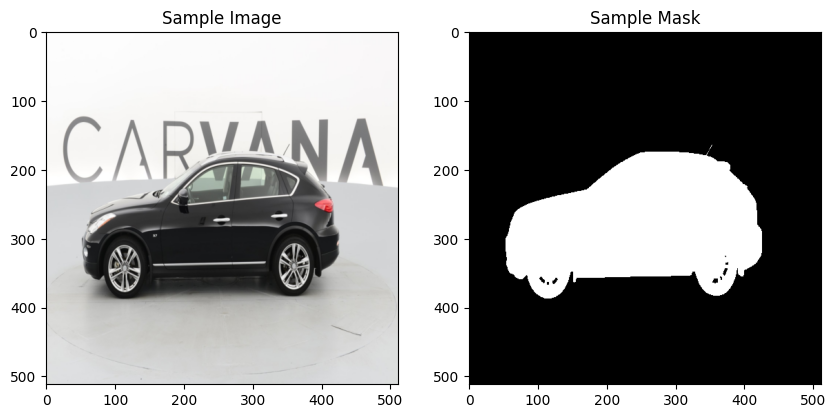

Unique values in sample mask: tensor([0.0000, 0.0039])
Shape of sample mask: torch.Size([1, 512, 512])


In [18]:
# Display a sample mask from the training dataset to ensure it's not empty
sample_img, sample_mask, _ = train_dataset[0] # Get a sample from the training dataset

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(sample_img.permute(1, 2, 0))
plt.title("Sample Image")

plt.subplot(1, 2, 2)
plt.imshow(sample_mask.squeeze(), cmap='gray') # Squeeze to remove channel dimension for grayscale
plt.title("Sample Mask")
plt.show()

print(f"Unique values in sample mask: {torch.unique(sample_mask)}")
print(f"Shape of sample mask: {sample_mask.shape}")

In [ ]:
epochs_list = list(range(1, EPOCHS + 1))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_list, train_losses, label='Training Loss')
plt.plot(epochs_list, val_losses, label='Validation Loss')
plt.xticks(ticks=list(range(1, EPOCHS + 1, 1)))
plt.title('Loss over epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid()
plt.tight_layout()
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_list, train_dcs, label='Training DICE')
plt.plot(epochs_list, val_dcs, label='Validation DICE')
plt.xticks(ticks=list(range(1, EPOCHS + 1, 1)))
plt.title('DICE Coefficient over epochs')
plt.xlabel('Epochs')
plt.ylabel('DICE')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
epochs_list = list(range(1, EPOCHS + 1))

plt.figure(figsize=(12, 5))
plt.plot(epochs_list, train_losses, label='Training Loss')
plt.plot(epochs_list, val_losses, label='Validation Loss')
plt.xticks(ticks=list(range(1, EPOCHS + 1, 1)))
plt.ylim(0, 0.05)
plt.title('Loss over epochs (zoomed)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid()
plt.tight_layout()

plt.legend()
plt.show()

In [ ]:
model_pth = '/content/my_checkpoint.pth'
trained_model = UNet(in_channels=3, num_classes=1).to(device)
trained_model.load_state_dict(torch.load(model_pth, map_location=torch.device(device)))

In [ ]:
test_running_loss = 0
test_running_dc = 0

with torch.no_grad():
  for idx, img_mask in enumerate(tqdm(test_dataloader, position=0, leave=True)):
    img = img_mask[0].float().to(device)
    mask = img_mask[1].float().to(device)

    y_pred = trained_model(img)
    loss = criterion(y_pred, mask)
    dc = dice_coefficient(y_pred, mask)

    test_running_loss += loss.item()
    test_running_dc += dc.item()

  test_loss = test_running_loss / (idx + 1)
  test_dc = test_running_dc / (idx + 1)

In [ ]:
def random_images_inference(image_tensors, mask_tensors, image_paths, model_pth, device):
  model = UNet(in_channels=3, num_classes=1).to(device)
  model.load_state_dict(torch.load(model_pth, map_location=torch.device(device)))
  transform = transforms.Compose([
    transforms.Resize((512, 512))
    ])
  # Iterate for the images, masks and paths
  for image_pth, mask_pth, image_paths in zip(image_tensors, mask_tensors, image_paths):

    # Load the image
    img = transform(image_pth)

    # Predict the image with the model (output are logits)
    y_pred_logits = model(img.unsqueeze(0))
    y_pred_logits = y_pred_logits.squeeze(0).permute(1,2,0)

    # Load the mask to compare
    mask = transform(mask_pth).permute(1, 2, 0).to(device)

    # Calculate DICE using the updated dice_coefficient (which now applies sigmoid and threshold)
    dc = dice_coefficient(y_pred_logits, mask)
    print(f"Image: {os.path.basename(image_paths)}, DICE coefficient: {round(float(dc),5)}")

    # Prepare predicted mask for display: apply sigmoid and threshold
    pred_mask_proba = torch.sigmoid(y_pred_logits)
    pred_mask_binary = (pred_mask_proba > 0.5).float() # Using 0.5 as threshold

    # Show the images
    img = img.cpu().detach().permute(1, 2, 0)
    pred_mask_display = pred_mask_binary.cpu().detach() # Use the binarized mask for display

    plt.figure(figsize=(15, 16))
    plt.subplot(131), plt.imshow(img), plt.title("original")
    plt.subplot(132), plt.imshow(pred_mask_display, cmap="gray"), plt.title("predicted")
    plt.subplot(133), plt.imshow(mask, cmap="gray"), plt.title("mask")
    plt.show()

In [ ]:
n = 10

image_tensors = []
mask_tensors = []
image_paths = []

for _ in range(n):
    random_index = random.randint(0, len(test_dataloader.dataset) - 1)
    random_sample = test_dataloader.dataset[random_index]
    image_tensors.append(random_sample[0])
    mask_tensors.append(random_sample[1])
    image_paths.append(random_sample[2])

In [ ]:
model_path = '/content/my_checkpoint.pth'

random_images_inference(image_tensors, mask_tensors, image_paths, model_path, device="cpu")

# Task
Adjust the `BCEWithLogitsLoss` to account for class imbalance by calculating and applying a `pos_weight` based on the distribution of foreground and background pixels in the training masks. Then, retrain the U-Net model for 25 epochs with this weighted loss, re-evaluate its performance on the test set, and finally, summarize how the weighted loss impacts the model's DICE coefficient and segmentation predictions.

## Calculate Positive Class Weight

### Subtask:
Compute the `pos_weight` for `BCEWithLogitsLoss` based on the distribution of foreground and background pixels in the training masks. This helps address class imbalance where car pixels are sparse.


**Reasoning**:
The first step is to initialize the foreground and background pixel counters to zero before iterating through the training dataset.



In [19]:
foreground_pixel_count = 0
background_pixel_count = 0
print("Initialized foreground and background pixel counts.")

Initialized foreground and background pixel counts.


**Reasoning**:
To calculate the `pos_weight`, I need to iterate through the `train_dataloader` and count the foreground and background pixels in each mask. This will allow me to sum the total counts across the entire training dataset.



In [20]:
for idx, img_mask in enumerate(tqdm(train_dataloader, desc="Counting Pixels", position=0, leave=True)):
    mask = img_mask[1].cpu().numpy()
    foreground_pixel_count += np.sum(mask > 0)
    background_pixel_count += np.sum(mask == 0)

print("Finished counting pixels.")

Counting Pixels:   0%|          | 0/509 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Counting Pixels: 100%|██████████| 509/509 [02:47<00:00,  3.04it/s]

Finished counting pixels.


**Reasoning**:
After counting all foreground and background pixels across the training dataset, the next logical step is to calculate the `pos_weight` for the `BCEWithLogitsLoss` using the ratio of background to foreground pixels, and then print this value as required by the subtask.



In [21]:
foreground_pixel_count = 0
background_pixel_count = 0

for idx, img_mask in enumerate(tqdm(train_dataloader, desc="Counting Pixels", position=0, leave=True)):
    mask = img_mask[1].cpu().numpy()
    foreground_pixel_count += np.sum(mask > 0)
    background_pixel_count += np.sum(mask == 0)

print("Finished counting pixels.")

pos_weight = torch.tensor(background_pixel_count / foreground_pixel_count)
print(f"Calculated pos_weight: {pos_weight.item():.4f}")

Counting Pixels:   0%|          | 0/509 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Counting Pixels: 100%|██████████| 509/509 [02:45<00:00,  3.08it/s]

Finished counting pixels.
Calculated pos_weight: 3.7445


**Reasoning**:
Now that `pos_weight` has been calculated, I need to redefine the `criterion` (BCEWithLogitsLoss) to include this weight to address class imbalance. The original `criterion` (cell `iAg0CLlS-miD`) needs to be updated with the calculated `pos_weight`.



In [22]:
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))
print(f"Criterion updated with pos_weight: {pos_weight.item():.4f}")

Criterion updated with pos_weight: 3.7445


## Retrain Model with Weighted Loss

### Subtask:
Re-run the training process with the updated, weighted `BCEWithLogitsLoss` for the specified number of epochs (25). This should help the model learn to segment foreground pixels and improve the DICE coefficient.


**Reasoning**:
The subtask requires retraining the model with the newly calculated `pos_weight` in the `BCEWithLogitsLoss`. This involves re-running the training loop cell that was previously executed to train the UNet model.



In [ ]:
EPOCHS = 25

train_losses = []
train_dcs = []
val_losses = []
val_dcs = []

for epoch in tqdm(range(EPOCHS)):
  model.train()
  train_running_loss = 0
  train_running_dc = 0

  for idx, img_mask in enumerate(tqdm(train_dataloader, position=0, leave=True)):
    img = img_mask[0].float().to(device)
    mask = img_mask[1].float().to(device)

    y_pred = model(img)
    optimizer.zero_grad()

    dc = dice_coefficient(y_pred, mask)
    loss = criterion(y_pred, mask)

    train_running_loss += loss.item()
    train_running_dc += dc.item()

    loss.backward()
    optimizer.step()

  train_loss = train_running_loss / (idx + 1)
  train_dc = train_running_dc / (idx + 1)

  train_losses.append(train_loss)
  train_dcs.append(train_dc)

  model.eval()
  val_running_loss = 0
  val_running_dc = 0

  with torch.no_grad():
    for idx, img_mask in enumerate(tqdm(val_dataloader, position=0, leave=True)):
      img = img_mask[0].float().to(device)
      mask = img_mask[1].float().to(device)

      y_pred = model(img)
      loss = criterion(y_pred, mask)
      dc = dice_coefficient(y_pred, mask)

      val_running_loss += loss.item()
      val_running_dc += dc.item()

    val_loss = val_running_loss / (idx + 1)
    val_dc = val_running_dc / (idx + 1)

  val_losses.append(val_loss)
  val_dcs.append(val_dc)

  print("-" * 30)
  print(f"Training Loss EPOCH {epoch + 1}: {train_loss:.4f}")
  print(f"Training DICE EPOCH {epoch + 1}: {train_dc:.4f}")
  print("\n")
  print(f"Validation Loss EPOCH {epoch + 1}: {val_loss:.4f}")
  print(f"Validation DICE EPOCH {epoch + 1}: {val_dc:.4f}")
  print("-" * 30)

# Saving the model
torch.save(model.state_dict(), 'my_checkpoint.pth')

  0%|          | 0/509 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
